# Set Transformer ve Normal Transformer Farkı

Bu notebook, **normal/sekans Transformer** ile **Set Transformer** arasındaki farkı teori, küçük NumPy deneyleri ve Orbit Wars mimarisi üzerinden anlatır.

Odak noktaları:
- Normal Transformer'ın neden çoğu kullanımda sıra/pozisyon varsayımı taşıdığı
- Set Transformer'ın permutation equivariance ve permutation invariance hedefleri
- SAB, ISAB ve PMA bloklarının ne yaptığı
- MAB/SAB/ISAB/PMA/mask bloklarının görsel şemalarla nasıl okunacağı
- Normal Transformer ve Set Transformer bloklarının paper-style diyagramlarla karşılaştırılması
- Aynı blokların PyTorch sınıflarıyla nasıl implemente edildiği
- Aynı self-attention çekirdeğinin set verisine nasıl farklı bir mimari disiplinle uygulandığı
- Orbit Wars'ta gezegen/fleet gözlemlerinin neden doğal olarak set problemi olduğu

## 0. Hızlı Özet

| Soru | Normal Transformer | Set Transformer |
| --- | --- | --- |
| Doğal veri tipi | Sekans: kelime dizisi, zaman serisi, token sırası anlamlı veri | Set: gezegenler, noktalar, objeler, örnek torbaları; sıra anlamsız |
| Pozisyon bilgisi | Genellikle absolute/relative positional encoding kullanır | Genellikle absolute slot positional encoding kullanmaz; gerekirse pairwise/geometrik bias kullanır |
| Simetri hedefi | Sırayı modellemek | Eleman sırası değişse de aynı set anlamını korumak |
| Set-to-set çıktı | Pozisyonlara bağlıdır; slot sırası değişince çıktı semantiği de değişebilir | Permutation equivariant: girdi elemanları permute edilirse eleman çıktıları aynı permütasyonla taşınır |
| Set-to-one çıktı | `[CLS]`, son token veya pool kullanabilir; pozisyon kullanımı sonucu değiştirebilir | Permutation invariant pooling: mean/sum/PMA gibi sıralamadan bağımsız özet |
| Tipik blok | Self-attention + FFN + positional encoding + mask; sekans sırasını korumak için tasarlanır | MAB/SAB ile set elemanı etkileşimi, ISAB ile verimli yaklaşık attention, PMA ile invariant pooling + mask |
| Orbit Wars yorumu | Gezegenleri keyfi bir dizi gibi görmek slot sırasına duyarlılık doğurabilir | Gezegen/fleet tokenlarını set gibi işler; global/value başlığı set özeti üretir |

## 1. Problem: Sıra mı, Küme mi?

Transformer kelimesi tek başına attention tabanlı bir blok ailesini anlatır. Fark çoğu zaman attention formülünden değil, **veriye dayatılan simetriden** gelir.

Bir cümlede sıra anlamlıdır:

```text
ajan gezegeni aldı  !=  gezegeni ajan aldı
```

Ama bir haritadaki gezegen listesinde sıra çoğu zaman sadece veri yapısının yan ürünüdür:

```text
{A, B, C, D}  ==  {C, A, D, B}
```

Orbit Wars'ta gezegenlerin ve fleetlerin liste sırası oyunun fiziksel anlamı değildir. Anlamı belirleyen şey; sahiplik, gemi sayısı, üretim, konum, gelen fleetler ve diğer objelerle ilişkidir. Bu yüzden modelin keyfi liste sırasına değil, objeler arası ilişkilere odaklanması istenir.

## 2. Sembol Sözlüğü

| Sembol | Anlam |
| --- | --- |
| $X \in \mathbb{R}^{n \times d}$ | $n$ elemanlı set/sekans; her eleman $d$ boyutlu feature |
| $P$ | Permütasyon matrisi; satırların sırasını değiştirir |
| $F(X)$ | Set-to-set encoder; her eleman için çıktı üretir |
| $g(X)$ | Set-to-one encoder/pooling; tek global çıktı üretir |
| $\mathrm{Equivariant}$ | $F(PX) = P F(X)$ |
| $\mathrm{Invariant}$ | $g(PX) = g(X)$ |

İki temel hedef var:

1. **Permutation equivariance:** Gezegenlerin sırasını değiştirirsem, gezegen başına üretilen logit/embedding de aynı şekilde yer değiştirsin.
2. **Permutation invariance:** Tüm harita için value gibi tek bir çıktı istiyorsam, gezegenlerin liste sırası sonucu değiştirmesin.

## 3. Normal Transformer Ne Yapar?

Temel self-attention formülü:

$$
\mathrm{Attn}(X) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V
$$

$$
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
$$

Önemli nüans: **Pozisyon eklenmemiş saf self-attention aslında permutation equivariant'tır.** Yani sadece satırları karıştırırsak çıktı satırları da aynı şekilde karışır.

Normal sekans Transformer kullanımında ise genellikle şu ekler vardır:

- Absolute veya relative positional encoding
- Causal mask veya sekans yapısını koruyan attention maskeleri
- İlk token, son token ya da belirli pozisyondaki tokena özel anlam yükleme

Bu ekler dil ve zaman serisi için doğrudur, çünkü pozisyon anlam taşır. Fakat set verisinde keyfi slot pozisyonu anlam taşımıyorsa, bu tasarım modelin yanlış bir sinyal öğrenmesine neden olabilir.

## 4. Set Transformer Ne Yapar?

Set Transformer, attention'ı set simetrisine uygun şekilde paketler. Ana fikir: **elemanlar etkileşsin, ama keyfi sıralama modele bilgi gibi sunulmasın.**

Bu bölümde blokları teori ve PyTorch layer karşılığıyla aynı sırada okuyacağız. Kodlar öğretim amaçlı minimaldir; Orbit Wars'taki `model.py` bunlara ek olarak edge bias, type embedding, action mask ve policy/value head gibi domain parçaları kullanır.

### 4.1 PyTorch Setup

Aşağıdaki hücre sadece import ve küçük bir güvenlik bayrağı kurar. Kernel ortamında PyTorch yoksa sonraki PyTorch hücreleri hata vermek yerine kısa mesaj basar.

In [ ]:
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ModuleNotFoundError:
    TORCH_AVAILABLE = False
    torch = None
    nn = None
    F = None
    print("Bu bölüm PyTorch ister. Kernel ortamında torch yoksa kod hücreleri atlanır.")
else:
    TORCH_AVAILABLE = True
    torch.manual_seed(7)
    print("torch", torch.__version__)


### 4.2 AttentionBlock: Attention Çekirdeğini Açık Yazalım

MAB, SAB, ISAB ve PMA'nın içinde aynı temel attention çekirdeği vardır:

$$
Q = XW_Q,\quad K = YW_K,\quad V = YW_V
$$

$$
\mathrm{Attention}(X,Y,Y) = \mathrm{softmax}\left(\frac{QK^\top}{\sqrt{d_h}} + M\right)V
$$

PyTorch'ta bunu `nn.MultiheadAttention` ile tek satırda çağırabiliriz. Burada eğitim amacıyla layerları açık yazıyoruz:

- `q_proj`, `k_proj`, `v_proj`: Q/K/V lineer projeksiyonları
- `head split`: `[B,T,D] -> [B,H,T,Dh]`
- `scores`: scaled dot-product attention skoru
- `key_padding_mask`: padded key slotlarını softmax dışına atar
- `out_proj`: head'leri birleştirdikten sonra son lineer projeksiyon

In [ ]:
if not globals().get("TORCH_AVAILABLE", False):
    print("AttentionBlock tanımlanmadı: PyTorch setup hücresini torch kurulu bir kernelde çalıştırın.")
else:
    class AttentionBlock(nn.Module):
        """
        Explicit multi-head scaled dot-product attention.

        query: [B, N, D]
        key:   [B, M, D]
        value: [B, M, D]
        key_padding_mask: optional [B, M], True olan key slotları maskelenir.

        Output:
            out: [B, N, D]
            attn_weights: [B, H, N, M]
        """

        def __init__(self, dim: int, num_heads: int, dropout: float = 0.0):
            super().__init__()
            if dim % num_heads != 0:
                raise ValueError("dim, num_heads'e tam bölünmeli.")

            self.dim = dim
            self.num_heads = num_heads
            self.head_dim = dim // num_heads
            self.scale = self.head_dim ** -0.5

            self.q_proj = nn.Linear(dim, dim)
            self.k_proj = nn.Linear(dim, dim)
            self.v_proj = nn.Linear(dim, dim)
            self.out_proj = nn.Linear(dim, dim)
            self.dropout = nn.Dropout(dropout)

        def _split_heads(self, x: torch.Tensor) -> torch.Tensor:
            B, T, D = x.shape
            x = x.view(B, T, self.num_heads, self.head_dim)
            return x.transpose(1, 2)  # [B, H, T, Dh]

        def _merge_heads(self, x: torch.Tensor) -> torch.Tensor:
            B, H, T, Dh = x.shape
            x = x.transpose(1, 2).contiguous()
            return x.view(B, T, H * Dh)  # [B, T, D]

        def forward(
            self,
            query: torch.Tensor,
            key: torch.Tensor,
            value: torch.Tensor,
            key_padding_mask: torch.Tensor | None = None,
        ):
            Q = self._split_heads(self.q_proj(query))
            K = self._split_heads(self.k_proj(key))
            V = self._split_heads(self.v_proj(value))

            scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale

            if key_padding_mask is not None:
                scores = scores.masked_fill(
                    key_padding_mask[:, None, None, :],
                    torch.finfo(scores.dtype).min,
                )

            attn_weights = torch.softmax(scores, dim=-1)
            attn_weights = torch.nan_to_num(attn_weights, nan=0.0)
            attn_weights = self.dropout(attn_weights)

            out = torch.matmul(attn_weights, V)
            out = self._merge_heads(out)
            out = self.out_proj(out)
            return out, attn_weights


    B, N, M, D = 2, 3, 5, 16
    q = torch.randn(B, N, D)
    kv = torch.randn(B, M, D)
    attn = AttentionBlock(dim=D, num_heads=4)
    out, weights = attn(q, kv, kv)
    print("out", tuple(out.shape), "weights", tuple(weights.shape))


### 4.3 MAB: Multihead Attention Block

MAB, Set Transformer'ın temel attention bloğudur. `X` query seti, `Y` key/value setidir.

$$
H = \mathrm{LayerNorm}\left(X + \mathrm{Attention}(X,Y,Y)\right)
$$

$$
\mathrm{MAB}(X,Y) = \mathrm{LayerNorm}\left(H + \mathrm{FFN}(H)\right)
$$

Layer karşılığı:

- `AttentionBlock`: query setin key/value seti okuması
- `ln1`: attention residual sonrası normalizasyon
- `ffn`: token-wise feed-forward network
- `ln2`: FFN residual sonrası normalizasyon

In [ ]:
if not globals().get("TORCH_AVAILABLE", False):
    print("MAB tanımlanmadı: PyTorch setup hücresini torch kurulu bir kernelde çalıştırın.")
else:
    class MAB(nn.Module):
        """
        Multihead Attention Block.

        X: query input      -> [B, N, D]
        Y: key/value input  -> [B, M, D]
        Output              -> [B, N, D]
        """

        def __init__(
            self,
            dim: int,
            num_heads: int,
            ff_hidden_dim: int | None = None,
            dropout: float = 0.0,
        ):
            super().__init__()
            ff_hidden_dim = ff_hidden_dim or dim * 4

            self.attn = AttentionBlock(dim, num_heads, dropout=dropout)
            self.ln1 = nn.LayerNorm(dim)
            self.ln2 = nn.LayerNorm(dim)
            self.ffn = nn.Sequential(
                nn.Linear(dim, ff_hidden_dim),
                nn.ReLU(),
                nn.Linear(ff_hidden_dim, dim),
            )

        def forward(
            self,
            X: torch.Tensor,
            Y: torch.Tensor,
            key_padding_mask: torch.Tensor | None = None,
        ):
            attn_out, _ = self.attn(
                query=X,
                key=Y,
                value=Y,
                key_padding_mask=key_padding_mask,
            )
            H = self.ln1(X + attn_out)
            ff_out = self.ffn(H)
            return self.ln2(H + ff_out)


    B, N, M, D = 2, 3, 5, 16
    X_demo = torch.randn(B, N, D)
    Y_demo = torch.randn(B, M, D)
    mab = MAB(dim=D, num_heads=4)
    print("MAB output", tuple(mab(X_demo, Y_demo).shape))


### 4.4 SAB: Self-Attention Block

SAB, MAB'in self-attention halidir:

$$
\mathrm{SAB}(X)=\mathrm{MAB}(X,X)
$$

Normal Transformer encoder self-attention'a en çok benzeyen Set Transformer bloğudur. Farkı: burada absolute positional encoding yoktur; set elemanları sıra bilgisi dayatılmadan birbirini okur.

In [ ]:
if not globals().get("TORCH_AVAILABLE", False):
    print("SAB tanımlanmadı: PyTorch setup hücresini torch kurulu bir kernelde çalıştırın.")
else:
    class SAB(nn.Module):
        """Set Attention Block: SAB(X) = MAB(X, X)."""

        def __init__(
            self,
            dim: int,
            num_heads: int,
            ff_hidden_dim: int | None = None,
            dropout: float = 0.0,
        ):
            super().__init__()
            self.mab = MAB(dim, num_heads, ff_hidden_dim, dropout=dropout)

        def forward(
            self,
            X: torch.Tensor,
            key_padding_mask: torch.Tensor | None = None,
        ):
            return self.mab(X, X, key_padding_mask=key_padding_mask)


    B, N, D = 2, 6, 16
    X_demo = torch.randn(B, N, D)
    sab = SAB(dim=D, num_heads=4)
    out = sab(X_demo)
    out_perm = sab(X_demo[:, torch.randperm(N)])
    print("SAB output", tuple(out.shape))
    print("SAB set-to-set çıktıdır; permütasyon testi için aşağıdaki NumPy bölümüne bakın.")


### 4.5 ISAB: Induced Self-Attention Block

ISAB, full self-attention'ın $O(n^2)$ maliyetini azaltmak için öğrenilen inducing pointler kullanır.

$$
H = \mathrm{MAB}(I, X)
$$

$$
\mathrm{ISAB}(X)=\mathrm{MAB}(X,H)
$$

Layer karşılığı:

- `inducing_points`: öğrenilen `[1, M, D]` parametresi
- `mab1`: inducing query'leri seti okur ve ara özet `H` üretir
- `mab2`: gerçek set elemanları bu özeti okuyarak güncellenir

In [ ]:
if not globals().get("TORCH_AVAILABLE", False):
    print("ISAB tanımlanmadı: PyTorch setup hücresini torch kurulu bir kernelde çalıştırın.")
else:
    class ISAB(nn.Module):
        """Induced Set Attention Block."""

        def __init__(
            self,
            dim: int,
            num_heads: int,
            num_inducing_points: int,
            ff_hidden_dim: int | None = None,
            dropout: float = 0.0,
        ):
            super().__init__()
            self.inducing_points = nn.Parameter(
                torch.randn(1, num_inducing_points, dim)
            )
            self.mab1 = MAB(dim, num_heads, ff_hidden_dim, dropout=dropout)
            self.mab2 = MAB(dim, num_heads, ff_hidden_dim, dropout=dropout)

        def forward(
            self,
            X: torch.Tensor,
            key_padding_mask: torch.Tensor | None = None,
        ):
            batch_size = X.size(0)
            I = self.inducing_points.expand(batch_size, -1, -1)
            H = self.mab1(I, X, key_padding_mask=key_padding_mask)
            return self.mab2(X, H)


    B, N, D = 2, 20, 16
    X_demo = torch.randn(B, N, D)
    isab = ISAB(dim=D, num_heads=4, num_inducing_points=8)
    print("ISAB output", tuple(isab(X_demo).shape))


### 4.6 PMA: Pooling by Multihead Attention

PMA, set'i fixed-size output'a çevirir:

$$
\mathrm{PMA}(X)=\mathrm{MAB}(S,X)
$$

`S`, öğrenilen seed vektörleridir. `num_seeds=1` ise tek global özet tokenı çıkar; bu value head veya classification head gibi set-to-one problemler için kullanışlıdır.

In [ ]:
if not globals().get("TORCH_AVAILABLE", False):
    print("PMA tanımlanmadı: PyTorch setup hücresini torch kurulu bir kernelde çalıştırın.")
else:
    class PMA(nn.Module):
        """Pooling by Multihead Attention."""

        def __init__(
            self,
            dim: int,
            num_heads: int,
            num_seeds: int,
            ff_hidden_dim: int | None = None,
            dropout: float = 0.0,
        ):
            super().__init__()
            self.seed_vectors = nn.Parameter(torch.randn(1, num_seeds, dim))
            self.mab = MAB(dim, num_heads, ff_hidden_dim, dropout=dropout)

        def forward(
            self,
            X: torch.Tensor,
            key_padding_mask: torch.Tensor | None = None,
        ):
            batch_size = X.size(0)
            S = self.seed_vectors.expand(batch_size, -1, -1)
            return self.mab(S, X, key_padding_mask=key_padding_mask)


    B, N, D = 2, 20, 16
    X_demo = torch.randn(B, N, D)
    pma = PMA(dim=D, num_heads=4, num_seeds=1)
    print("PMA output", tuple(pma(X_demo).shape))


### 4.7 Mini SetTransformer: Blokları Uçtan Uca Bağlama

Son olarak raw set feature'larını modele sokalım:

```text
X [B,N,D_in]
  -> input_proj
  -> ISAB encoder stack
  -> PMA pooling
  -> output_head
  -> y [B, output_dim]
```

Bu, senin paylaştığın kullanım örneğindeki `SetTransformer(...)` sınıfını tamamlar.

In [ ]:
if not globals().get("TORCH_AVAILABLE", False):
    print("SetTransformer örneği çalışmadı: PyTorch setup hücresini torch kurulu bir kernelde çalıştırın.")
else:
    class SetTransformer(nn.Module):
        """Minimal set-to-one Set Transformer."""

        def __init__(
            self,
            input_dim: int,
            dim: int,
            output_dim: int,
            num_heads: int,
            num_inducing_points: int,
            num_seeds: int = 1,
            num_isab_layers: int = 2,
            ff_hidden_dim: int | None = None,
            dropout: float = 0.0,
        ):
            super().__init__()
            self.num_seeds = num_seeds
            self.input_proj = nn.Linear(input_dim, dim)
            self.encoder = nn.ModuleList([
                ISAB(
                    dim=dim,
                    num_heads=num_heads,
                    num_inducing_points=num_inducing_points,
                    ff_hidden_dim=ff_hidden_dim,
                    dropout=dropout,
                )
                for _ in range(num_isab_layers)
            ])
            self.pool = PMA(
                dim=dim,
                num_heads=num_heads,
                num_seeds=num_seeds,
                ff_hidden_dim=ff_hidden_dim,
                dropout=dropout,
            )
            self.output_head = nn.Sequential(
                nn.LayerNorm(dim),
                nn.Linear(dim, output_dim),
            )

        def forward(
            self,
            X: torch.Tensor,
            key_padding_mask: torch.Tensor | None = None,
        ):
            Z = self.input_proj(X)
            for block in self.encoder:
                Z = block(Z, key_padding_mask=key_padding_mask)
            pooled = self.pool(Z, key_padding_mask=key_padding_mask)
            out = self.output_head(pooled)

            if self.num_seeds == 1:
                return out.squeeze(1)  # [B, output_dim]
            return out                 # [B, num_seeds, output_dim]


    B = 8       # batch size
    N = 20      # set eleman sayısı
    D_in = 10   # input feature dimension

    X = torch.randn(B, N, D_in)

    model = SetTransformer(
        input_dim=D_in,
        dim=64,
        output_dim=3,
        num_heads=4,
        num_inducing_points=8,
        num_seeds=1,
    )

    y = model(X)
    print("y.shape:", y.shape)

    # Set-to-one modelde sıra değişimi sonucu değiştirmemeli.
    perm = torch.randperm(N)
    y_perm = model(X[:, perm])
    print("permutation invariance max error:", (y_perm - y).abs().max().item())


In [ ]:
import numpy as np

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

print("NumPy", np.__version__)

## 5. Küçük Deney: Gezegenleri Karıştırınca Ne Olur?

Aşağıdaki toy veri bir mini gezegen seti gibi düşünülebilir. Feature'lar normalize edilmiş basit değerlerdir:

- sahiplik: self/enemy/neutral
- gemi sayısı
- production
- konum sin/cos benzeri iki koordinat

Burada amaç gerçek Orbit Wars feature setini tekrar kurmak değil; sıranın model davranışına etkisini çıplak görmek.

In [ ]:
feature_names = ["is_self", "is_enemy", "is_neutral", "ships", "production", "x", "y"]
planet_names = np.array(["own_alpha", "enemy_beta", "neutral_gamma", "own_delta", "enemy_eps"])

X = np.array([
    [1, 0, 0, 0.70, 0.60, 0.20, 0.80],
    [0, 1, 0, 0.55, 0.40, 0.75, 0.25],
    [0, 0, 1, 0.10, 0.20, 0.50, 0.50],
    [1, 0, 0, 0.30, 0.30, 0.15, 0.45],
    [0, 1, 0, 0.85, 0.70, 0.90, 0.65],
], dtype=np.float64)

perm = np.array([2, 0, 4, 1, 3])
X_perm = X[perm]
planet_names_perm = planet_names[perm]

print("Orijinal sıra:", planet_names.tolist())
print("Karıştırılmış sıra:", planet_names_perm.tolist())
print("Feature shape:", X.shape)

In [ ]:
def softmax(a, axis=-1):
    a = a - np.max(a, axis=axis, keepdims=True)
    exp = np.exp(a)
    return exp / np.sum(exp, axis=axis, keepdims=True)


def self_attention(X, Wq, Wk, Wv):
    Q = X @ Wq
    K = X @ Wk
    V = X @ Wv
    scores = (Q @ K.T) / np.sqrt(Q.shape[-1])
    weights = softmax(scores, axis=-1)
    return weights @ V, weights


def cross_attention(Q_input, KV_input, Wq, Wk, Wv):
    Q = Q_input @ Wq
    K = KV_input @ Wk
    V = KV_input @ Wv
    scores = (Q @ K.T) / np.sqrt(Q.shape[-1])
    weights = softmax(scores, axis=-1)
    return weights @ V, weights


d_in = X.shape[1]
d_model = 8
Wq = rng.normal(scale=0.35, size=(d_in, d_model))
Wk = rng.normal(scale=0.35, size=(d_in, d_model))
Wv = rng.normal(scale=0.35, size=(d_in, d_model))

H, A = self_attention(X, Wq, Wk, Wv)
H_perm, A_perm = self_attention(X_perm, Wq, Wk, Wv)

equivariance_error = np.max(np.abs(H_perm - H[perm]))
attention_error = np.max(np.abs(A_perm - A[np.ix_(perm, perm)]))

print("Saf self-attention equivariance hatası:", equivariance_error)
print("Attention matrisi permütasyon hatası:", attention_error)

Sonuç çok küçük bir nümerik hata dışında sıfırdır. Bu şu demek:

$$
\mathrm{SelfAttn}(PX) = P\,\mathrm{SelfAttn}(X)
$$

Yani saf self-attention tek başına set düşmanı değildir. Set Transformer ile normal Transformer arasındaki pratik fark; pozisyon encoding'i, pooling biçimi, maskeler ve mimarinin hangi simetriyi korumak üzere kurulduğudur.

In [ ]:
# Normal sekans Transformer kullanımını temsil etmek için slot pozisyonlarına
# bağlı bir positional embedding ekleyelim. Objeler karıştırılınca pozisyonlar
# objelerle birlikte taşınmıyor; slotlara sabit kalıyor.
positional = rng.normal(scale=0.20, size=X.shape)

H_seq, _ = self_attention(X + positional, Wq, Wk, Wv)
H_seq_perm, _ = self_attention(X_perm + positional, Wq, Wk, Wv)

position_sensitive_error = np.max(np.abs(H_seq_perm - H_seq[perm]))

print("Pozisyon eklenince equivariance hatası:", round(float(position_sensitive_error), 6))
print("Bu değerin sıfırdan büyük olması, slot sırasının modele bilgi olarak girdiğini gösterir.")

## 6. Tipik Blok Satırını Açalım

Tablodaki `Tipik blok` satırı birkaç farklı parçayı sıkıştırıyor. Bu bölümde her parçayı ayrı ayrı açacağız:

![Normal Transformer ve Set Transformer paper-style blok diyagramları](assets/transformer_blocks/paper_style_transformer_comparison.svg)

Bu ana figür iki aileyi aynı görsel dilde yan yana koyar: üst sıra normal Transformer'ın sekans encoder/decoder akışını, alt sıra Set Transformer'ın MAB/SAB/ISAB/PMA operasyonlarını gösterir. Normal Transformer tarafında `+ Pos` kutuları sıra bilgisinin modele verildiği noktadır; Set Transformer tarafında ise bloklar set elemanlarını absolute slot pozisyonu olmadan işler.


| Blok | Kısa formül | Ne zaman kullanılır? | Simetri davranışı |
| --- | --- | --- | --- |
| Normal Transformer block | `SelfAttn(X + Pos) + FFN` | Sıra/pozisyon anlamlıysa | Saf self-attention equivarianttır; slot positional encoding veya sıra maskesi sabit kalırsa set permütasyon equivariance'ı kırılır |
| MAB | `Attention(Q_set, KV_set)` | Bir setin başka bir seti okuması | Query sırası için equivariant; key/value birlikte aynı permütasyonla taşınırsa key/value sırasına invariant |
| SAB | `MAB(X, X)` | Set elemanlarının birbirini okuması | Permutation equivariant |
| ISAB | `MAB(X, MAB(I, X))` | Büyük setlerde daha ucuz attention | Full SAB'ye yaklaşık modelleme yapar; simetri olarak equivarianttır, maliyet $O(nm)$ |
| PMA | `MAB(S, X)` | Setten sabit sayıda özet token üretmek | Girdi seti sırasına invariant; birden fazla seed varsa çıktı seed sırasına göre sabit sıralıdır |
| Mask | Attention skorunda padded key'leri siler | Değişken boyutlu set/sekans | Padding maskesi tokenlarla birlikte permute edilirse simetriyi bozmaz; causal/sıra maskesi ise bozar |

Aşağıdaki kodlar eğitim amaçlı mini NumPy karşılıklarıdır. PyTorch'taki gerçek implementation daha vektörize, çok kafalı ve trainable parametre yönetimiyle gelir; ama simetri davranışı bu küçük fonksiyonlarda net görülebilir.

In [ ]:
def gelu(x):
    return 0.5 * x * (1.0 + np.tanh(np.sqrt(2.0 / np.pi) * (x + 0.044715 * x**3)))


def layer_norm(x, eps=1e-6):
    mean = x.mean(axis=-1, keepdims=True)
    var = x.var(axis=-1, keepdims=True)
    return (x - mean) / np.sqrt(var + eps)


def feed_forward(x, W1, b1, W2, b2):
    return gelu(x @ W1 + b1) @ W2 + b2


def attention_with_mask(Q_input, KV_input, Wq, Wk, Wv, key_mask=None):
    """Tek kafalı attention. key_mask=True olan key slotları softmax dışına atılır."""
    Q = Q_input @ Wq
    K = KV_input @ Wk
    V = KV_input @ Wv
    scores = (Q @ K.T) / np.sqrt(Q.shape[-1])

    if key_mask is not None:
        scores = scores.copy()
        scores[:, ~key_mask] = -1e9

    weights = softmax(scores, axis=-1)
    return weights @ V, weights


# Gerçek Transformer'da residual bağlantı için her şey d_model boyutundadır.
# Bu yüzden raw feature'ları önce ortak model uzayına projekte ediyoruz.
W_embed = rng.normal(scale=0.30, size=(d_in, d_model))
Wq_block = rng.normal(scale=0.25, size=(d_model, d_model))
Wk_block = rng.normal(scale=0.25, size=(d_model, d_model))
Wv_block = rng.normal(scale=0.25, size=(d_model, d_model))

# Normal sekans bloğundaki slot pozisyonu sinyali. Objeler permute edilse bile
# bu embedding slotlarda sabit kalır; set simetrisini kıran nokta budur.
positional = rng.normal(scale=0.20, size=X.shape)

hidden = 16
W1 = rng.normal(scale=0.20, size=(d_model, hidden))
b1 = np.zeros(hidden)
W2 = rng.normal(scale=0.20, size=(hidden, d_model))
b2 = np.zeros(d_model)


def embed_tokens(X_raw):
    return X_raw @ W_embed


print("Yardımcı layer fonksiyonları hazır.")

![ChatGPT Image May 7, 2026, 01_19_40 AM.png](<attachment:ChatGPT Image May 7, 2026, 01_19_40 AM.png>)
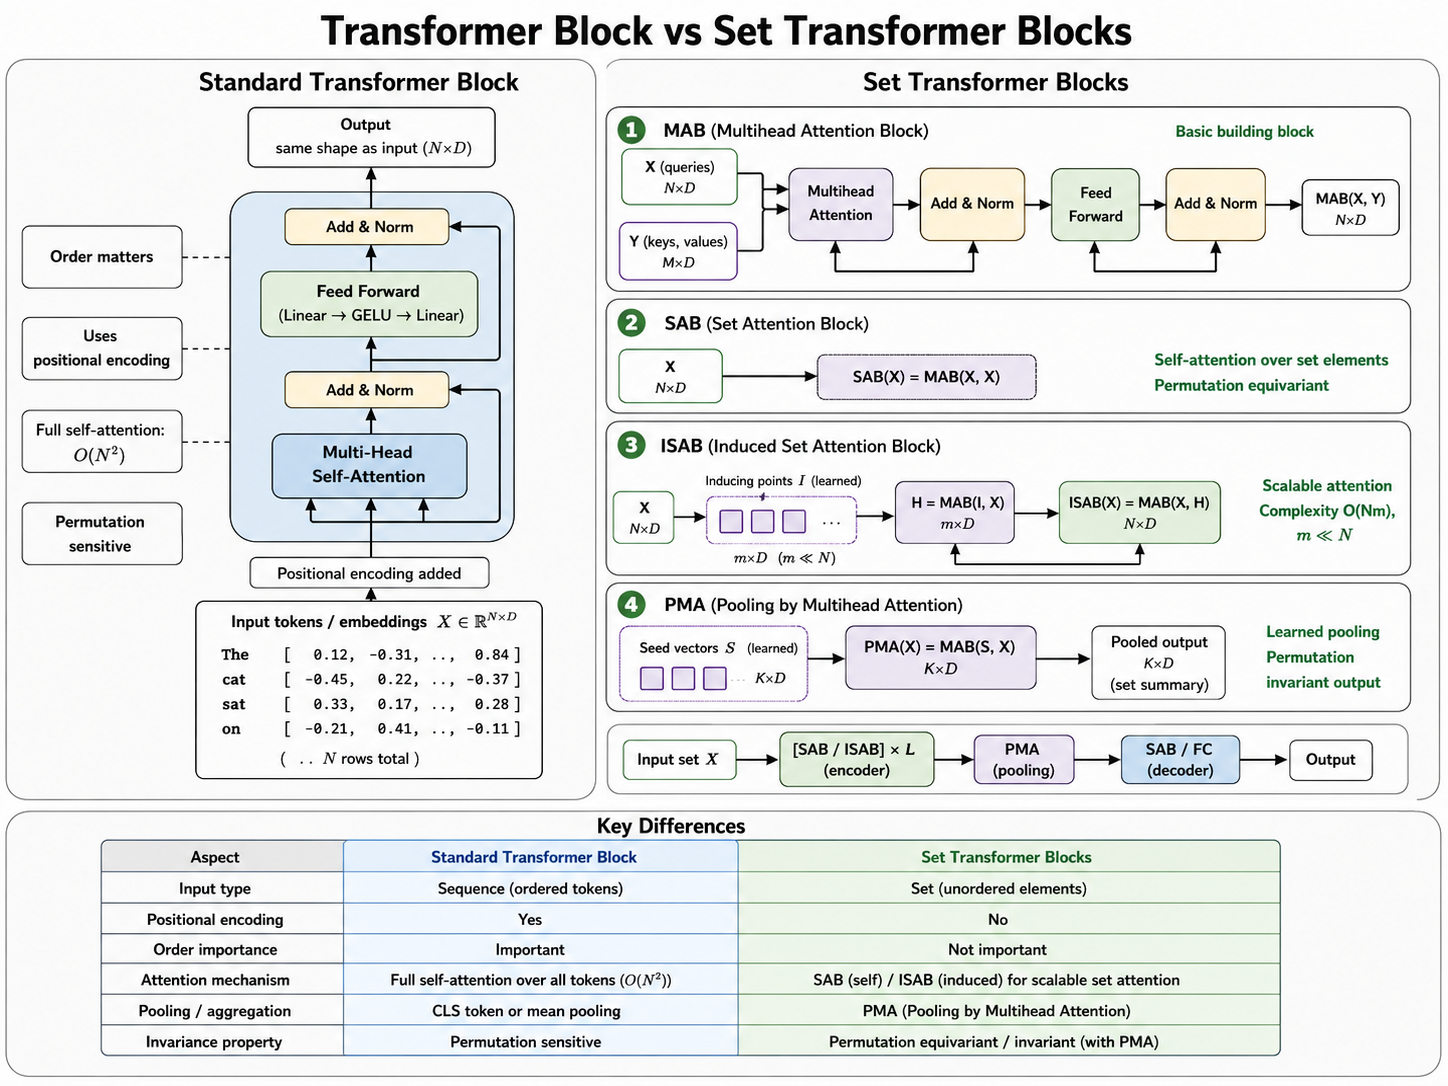

### 6.1 Normal Transformer Block: Self-Attention + FFN + Position/Mask

![Normal Transformer block](assets/transformer_blocks/normal_transformer_block.svg)

Görselde kırmızı `Pozisyon` kutusu kritik farktır: sekans Transformer'da token embedding'ine slot/konum bilgisi eklenir. Bu, cümle ve zaman serisi için doğru bir bias'tır; ama set verisinde keyfi slot sırasını modele anlamlıymış gibi gösterebilir.

Sekans Transformer bloğu genellikle şu mantıktadır:

$$
Z_0 = X + E_{pos}
$$

$$
Z_1 = Z_0 + \mathrm{SelfAttention}(\mathrm{LN}(Z_0))
$$

$$
Z_2 = Z_1 + \mathrm{FFN}(\mathrm{LN}(Z_1))
$$

Buradaki kritik parça `E_pos` yani positional encoding'dir. Dil modelinde bu gereklidir; tokenın cümledeki yeri anlam taşır. Fakat set verisinde slot pozisyonu keyfiyse, `planet_0` ve `planet_1` gibi pozisyonlar yapay anlam kazanır.

Nüans: Positional encoding ve sıra/causal maskesi olmayan saf self-attention aslında permutation equivarianttır. Equivariance'ın kırıldığı senaryo, set elemanlarını permute ederken slot positional embedding'lerini veya sıra maskesini sabit bırakmaktır. Sekans Transformer'ın normal kullanımında da zaten amaç budur: aynı token farklı pozisyonda farklı temsil alabilsin.

Kod karşılaştırması: Aynı objeleri permute edeceğiz. Positional embedding slotlara sabit kaldığı için çıktı artık aynı permütasyonu takip etmeyecek.

In [ ]:
def normal_transformer_block(X_raw, positional_raw, key_mask=None):
    Z0 = embed_tokens(X_raw + positional_raw)
    attn_out, weights = attention_with_mask(
        layer_norm(Z0), layer_norm(Z0), Wq_block, Wk_block, Wv_block, key_mask
    )
    Z1 = Z0 + attn_out
    Z2 = Z1 + feed_forward(layer_norm(Z1), W1, b1, W2, b2)
    return Z2, weights


normal_out, normal_w = normal_transformer_block(X, positional)
normal_out_perm, normal_w_perm = normal_transformer_block(X_perm, positional)

print("Normal block equivariance hatası:", np.max(np.abs(normal_out_perm - normal_out[perm])))
print("Yorum: Pozisyon slotlara bağlı kaldığı için bu değer sıfırdan büyük çıkar.")

### 6.2 MAB: Multihead Attention Block

![MAB block](assets/transformer_blocks/mab.svg)

Görselde `X` query setidir; çıktı sayısı `X` ile aynıdır. `Y` ise key/value setidir; `Y` içindeki elemanların sırası değişirse attention aynı objeleri farklı sırada görür ama weighted sum sonucu değişmez. Burada `Y`'nin key ve value olarak aynı sırayla permute edildiği varsayılır; sadece key'i veya sadece value'yu permute etmek aynı objenin anahtar/değer eşleşmesini bozar.

Set Transformer'ın temel yapı taşı MAB'dir:

$$
\mathrm{MAB}(X, Y) = \mathrm{FFN}\bigl(\mathrm{Attention}(X, Y, Y)\bigr)
$$

Daha ayrıntılı residual/pre-norm yazımıyla:

$$
H = X + \mathrm{Attention}(\mathrm{LN}(X), \mathrm{LN}(Y), \mathrm{LN}(Y))
$$

$$
\mathrm{MAB}(X,Y) = H + \mathrm{FFN}(\mathrm{LN}(H))
$$

Burada `X` query setidir, `Y` key/value setidir.

Önemli simetri:

- Query seti permute edilirse çıktı aynı şekilde permute olur.
- Key/value seti birlikte aynı permütasyonla permute edilirse çıktı değişmez, çünkü attention ağırlıkları aynı objeleri takip eder ve weighted sum aynı kalır.
- Key/value tarafında positional embedding veya yanlış taşınmış padding maskesi varsa bu invariance bozulabilir.

Bu yüzden MAB hem cross-attention hem de set pooling için ana tuğladır.

In [ ]:
def mab_from_embeddings(Q0, KV0, key_mask=None):
    attn_out, weights = attention_with_mask(
        layer_norm(Q0), layer_norm(KV0), Wq_block, Wk_block, Wv_block, key_mask
    )
    H = Q0 + attn_out
    out = H + feed_forward(layer_norm(H), W1, b1, W2, b2)
    return out, weights


def mab(Q_set_raw, KV_set_raw, key_mask=None):
    Q0 = embed_tokens(Q_set_raw)
    KV0 = embed_tokens(KV_set_raw)
    return mab_from_embeddings(Q0, KV0, key_mask=key_mask)


query = X[:2]       # iki adet query: örneğin iki kaynak gezegen adayı
kv = X              # tüm gezegen seti okunuyor
query_perm = query[[1, 0]]
kv_perm = kv[perm]

mab_out, _ = mab(query, kv)
mab_query_perm_out, _ = mab(query_perm, kv)
mab_kv_perm_out, _ = mab(query, kv_perm)

print("Query permütasyonu equivariance hatası:", np.max(np.abs(mab_query_perm_out - mab_out[[1, 0]])))
print("Key/value permütasyonu invariance hatası:", np.max(np.abs(mab_kv_perm_out - mab_out)))

### 6.3 SAB: Self-Attention Block

![SAB block](assets/transformer_blocks/sab.svg)

SAB, MAB'in en doğal set encoder halidir: aynı set hem query hem key/value olur. Bu yüzden her gezegen/fleet tokenı diğer tokenları okuyarak kendi temsilini günceller.

SAB, MAB'in self-attention halidir:

$$
\mathrm{SAB}(X) = \mathrm{MAB}(X, X)
$$

Her eleman diğer tüm elemanları okur. Planet örneğinde bir gezegen; düşman gezegenleri, kendi gezegenlerini ve neutral hedefleri aynı attention bloğunda değerlendirebilir.

SAB'nin çıktısı set-to-settir:

$$
\mathrm{SAB}(PX) = P\,\mathrm{SAB}(X)
$$

Bu nedenle source logit veya planet başına embedding üretmek için uygundur.

In [ ]:
def sab(X, key_mask=None):
    return mab(X, X, key_mask=key_mask)


sab_out, _ = sab(X)
sab_out_perm, _ = sab(X_perm)

print("SAB equivariance hatası:", np.max(np.abs(sab_out_perm - sab_out[perm])))

### 6.4 ISAB: Induced Self-Attention Block

![ISAB block](assets/transformer_blocks/isab.svg)

ISAB'de kırmızı `I` tokenları öğrenilen inducing pointlerdir. İlk MAB setten küçük bir özet çıkarır; ikinci MAB gerçek elemanları bu özet üzerinden günceller. Büyük setlerde hız kazancı buradan gelir.

Full SAB'de her eleman her elemana bakar; maliyet $O(n^2)$ olur. ISAB, öğrenilen az sayıda inducing point ile ara özet üretir:

$$
H = \mathrm{MAB}(I, X)
$$

$$
\mathrm{ISAB}(X) = \mathrm{MAB}(X, H)
$$

Burada:

- $I \in \mathbb{R}^{m \times d}$ öğrenilen inducing tokenlarıdır.
- İlk MAB, setten $m$ adet özet çıkarır.
- İkinci MAB, her gerçek elemanın bu özetleri okuyarak güncellenmesini sağlar.

Maliyet yaklaşık $O(nm)$ olur. $m \ll n$ ise büyük kazanç sağlar. Bedeli, full pairwise ilişkiyi doğrudan değil, inducing bottleneck üzerinden modellemesidir.

In [ ]:
m_inducing = 3
I = rng.normal(scale=0.40, size=(m_inducing, d_in))


def isab(X, inducing=I, key_mask=None):
    H, _ = mab(inducing, X, key_mask=key_mask)       # inducing tokenlar seti okur
    X0 = embed_tokens(X)
    out, _ = mab_from_embeddings(X0, H)              # gerçek elemanlar inducing özetleri okur
    return out, H


isab_out, inducing_summary = isab(X)
isab_out_perm, inducing_summary_perm = isab(X_perm)

print("ISAB çıktı equivariance hatası:", np.max(np.abs(isab_out_perm - isab_out[perm])))
print("Inducing özet invariance hatası:", np.max(np.abs(inducing_summary_perm - inducing_summary)))

### 6.5 PMA: Pooling by Multihead Attention

![PMA block](assets/transformer_blocks/pma.svg)

PMA'da seed token query rolündedir. Seed sayısı 1 ise tek global özet çıkar; birden fazla seed kullanılırsa setten sabit sayıda özet token üretilebilir.

PMA, setten sabit sayıda global token çıkarır:

$$
\mathrm{PMA}(X) = \mathrm{MAB}(S, X)
$$

$S$ öğrenilen seed tokenlarıdır. Eğer $S$ tek token ise set-to-one özet elde ederiz; $k$ seed varsa set-to-$k$ özet elde ederiz.

Mean pooling tüm elemanlara eşit ağırlık verir. PMA ise attention ile duruma göre ağırlık öğrenir. Örneğin value head için en kritik gezegenler daha yüksek ağırlık alabilir.

PMA invarianttır:

$$
\mathrm{PMA}(PX) = \mathrm{PMA}(X)
$$

In [ ]:
S = rng.normal(scale=0.50, size=(1, d_in))


def pma(X, seeds=S, key_mask=None):
    return mab(seeds, X, key_mask=key_mask)


pma_out, pma_w = pma(X)
pma_out_perm, pma_w_perm = pma(X_perm)

print("PMA invariance hatası:", np.max(np.abs(pma_out_perm - pma_out)))
print("\nPMA attention ağırlıkları, orijinal sıra:")
for name, w in zip(planet_names, pma_w[0]):
    print(f"  {name:>14}: {w:.4f}")
print("\nAynı ağırlıklar karıştırılmış sırada objeleri takip eder:")
for name, w in zip(planet_names_perm, pma_w_perm[0]):
    print(f"  {name:>14}: {w:.4f}")

### 6.6 Mask: Padding ve Legal Action Mask

![Mask flow](assets/transformer_blocks/mask.svg)

Mask, attention veya action softmax'ında geçersiz seçeneklerin olasılığa karışmasını engeller. Orbit Wars'ta padding mask modelin olmayan tokenlara bakmasını, source mask ise illegal launch kaynaklarını seçmesini engeller.

Mask bir layer gibi parametre öğrenmek zorunda değildir; ama Transformer davranışını belirleyen kritik bir parçadır.

Attention skorunda padded key'ler softmax öncesi çok negatif yapılır:

$$
\mathrm{softmax}\left(\frac{QK^\top}{\sqrt{d_k}} + M_{pad}\right)
$$

$$
M_{pad,j} = \begin{cases}
0 & \text{key } j \text{ gerçek token ise}\\
-\infty & \text{key } j \text{ padding ise}
\end{cases}
$$

Orbit Wars'ta iki farklı mask fikri var:

- `planet_mask`, `fleet_mask`: olmayan tokenlara attention verilmesini engeller.
- `source_mask`: rakip, neutral veya boş gezegenden launch seçilmesini engeller.

Aşağıdaki deneyde padded tokenın feature'ını aşırı değiştiriyoruz. Mask yoksa çıktı etkilenir; mask varsa gerçek tokenların çıktısı değişmez.

In [ ]:
X_pad = np.vstack([X, np.zeros((1, d_in))])
mask = np.array([True, True, True, True, True, False])

X_pad_changed = X_pad.copy()
X_pad_changed[-1] = 999.0  # padding slotu maskelenmezse attention'ı zehirleyebilir

masked_out, _ = sab(X_pad, key_mask=mask)
masked_changed_out, _ = sab(X_pad_changed, key_mask=mask)
unmasked_out, _ = sab(X_pad)
unmasked_changed_out, _ = sab(X_pad_changed)

print("Maskeli gerçek token farkı:", np.max(np.abs(masked_changed_out[:5] - masked_out[:5])))
print("Masksiz gerçek token farkı:", np.max(np.abs(unmasked_changed_out[:5] - unmasked_out[:5])))
print("Yorum: Maskeli durumda padding feature'ı değişse bile gerçek token çıktıları korunur.")

### 6.7 Blokları Bir Cümlede Ayırma

| Blok | Kod sezgisi | Teorik rol |
| --- | --- | --- |
| Normal Transformer block | `X + positional -> self-attn -> FFN` | Sıralı token ilişkilerini öğrenir; pozisyon anlamlıdır |
| MAB | `query_set` başka bir `kv_set` okur | Cross-attention; Set Transformer'ın genel attention operatörü |
| SAB | `mab(X, X)` | Set elemanlarını birbirine konuşturur; set-to-set equivariant encoder |
| ISAB | `mab(X, mab(I, X))` | Büyük setlerde inducing bottleneck ile daha ucuz set encoder |
| PMA | `mab(seed, X)` | Setten invariant global özet üretir |
| Mask | `scores[:, pad] = -inf` | Padding ve illegal seçimlerin olasılığa sızmasını engeller |

Orbit Wars'taki `TransformerBlock`, pratikte SAB benzeri encoder bloğudur; `edge_bias` ise normal Set Transformer anlatımına eklenen domain bilgisidir. Bu bias attention skoruna mesafe/yön ön bilgisi koyar ama gezegen slotlarını absolute pozisyon haline getirmez.

## 7. Set-to-One Çıktı: Pooling Nerede Kritikleşir?

Bir harita için tek value tahmini üretmek istiyorsak set-to-one fonksiyon gerekir.

- Mean/sum pooling, equivariant token çıktısını invariant özet haline getirir.
- PMA, öğrenilebilir seed query'leriyle daha esnek invariant özet üretir.
- İlk tokenı almak set için hatalıdır; ilk token sadece veri sırasına göre ilk olan objedir.

In [ ]:
mean_readout = H.mean(axis=0)
mean_readout_perm = H_perm.mean(axis=0)

first_token_readout = H[0]
first_token_readout_perm = H_perm[0]

print("Mean pooling invariant hata:", np.max(np.abs(mean_readout_perm - mean_readout)))
print("İlk token readout farkı:", np.linalg.norm(first_token_readout_perm - first_token_readout))
print("Karıştırılmış ilk token:", planet_names_perm[0])

In [ ]:
# PMA fikrinin küçük karşılığı: öğrenilen seed vektörü seti query'ler.
# Key/value sırası değişse bile weighted sum aynı kalır.
seed = rng.normal(scale=0.5, size=(1, d_in))

pma_readout, pma_weights = cross_attention(seed, X, Wq, Wk, Wv)
pma_readout_perm, pma_weights_perm = cross_attention(seed, X_perm, Wq, Wk, Wv)

print("PMA-benzeri readout invariant hata:", np.max(np.abs(pma_readout_perm - pma_readout)))
print("Orijinal attention ağırlıkları:")
for name, w in zip(planet_names, pma_weights[0]):
    print(f"  {name:>14}: {w:.4f}")
print("\nKarıştırılmış sıradaki ağırlıklar aynı objeleri takip eder:")
for name, w in zip(planet_names_perm, pma_weights_perm[0]):
    print(f"  {name:>14}: {w:.4f}")

## 8. Hesaplama Maliyeti

Normal full self-attention ve SAB aynı temel maliyeti taşır:

$$
O(n^2 d)
$$

Çünkü her eleman her elemanla attention skoru üretir. Set Transformer literatüründeki ISAB bu maliyeti inducing point sayısı $m$ ile düşürmeyi hedefler:

$$
O(n m d) \quad \text{yaklaşık, } m \ll n
$$

Orbit Wars gibi küçük/orta token sayılı ortamlarda full SAB pratik olabilir. Binlerce noktalı point cloud veya çok büyük event setlerinde ISAB daha anlamlı hale gelir.

In [ ]:
def cost_full_attention(n, d=128):
    return n * n * d


def cost_isab(n, m=16, d=128):
    # İki MAB olduğu için kabaca 2*n*m*d ölçeği.
    return 2 * n * m * d


print(f"{'n':>6} | {'full attention':>16} | {'ISAB m=16':>12} | {'oran':>8}")
print("-" * 55)
for n in [16, 32, 64, 128, 512, 2048]:
    full = cost_full_attention(n)
    isab = cost_isab(n)
    print(f"{n:6d} | {full:16,d} | {isab:12,d} | {full / isab:8.1f}x")

## 9. Mimari Karşılaştırma

### Normal sekans Transformer akışı

```text
token embedding + positional embedding
        ↓
Transformer blocks
        ↓
pozisyona bağlı çıktı: her token / CLS / son token
```

Bu akışta token 0, token 1, token 2 gibi pozisyonların ayrı anlam taşıması beklenir.

### Set Transformer akışı

```text
eleman feature projection (+ opsiyonel type/domain embedding)
        ↓
SAB veya ISAB blocks
        ↓
set-to-set: eleman başına çıktı
        ↓
PMA / mean / global seed ile set-to-one çıktı
```

Klasik Set Transformer tanımında type embedding zorunlu bir blok değildir; model çoğunlukla homojen set elemanları için `shared feature projection -> SAB/ISAB -> PMA` akışıyla anlatılır. Type/domain embedding, set içinde farklı türde elemanlar varsa eklenen pratik bir genişletmedir. Örneğin Orbit Wars'ta planet, fleet ve global token farklı türler olduğu için `model.py` içinde token type embedding kullanılır.

Önemli nüans: Type embedding slot pozisyonu gibi kullanılmamalıdır. `planet_3` ismi slot anlamı taşımamalı; sadece batch içinde bookkeeping için kullanılan yer olmalıdır. Eğer type embedding elemanın kendi tipiyle birlikte taşınıyorsa permutation equivariance bozulmaz. Ama type id sabit slotlara bağlanır ve elemanlar bu type id'lerle birlikte permute edilmezse simetri bozulur.

## 10. Orbit Wars Koduna Bağlantı

Bu repoda `model.py` doğrudan Set Transformer policy/value ağı olarak yazılmıştır. Üst yorumdaki token düzeni:

```text
[planet_0, ..., planet_{P-1}, fleet_0, ..., fleet_{F-1}, GLOBAL]
```

Önemli tasarım noktaları:

| Kod parçası | Set Transformer açısından anlamı |
| --- | --- |
| `planet_proj`, `fleet_proj`, `global_proj` | Heterojen feature tiplerini ortak `d_model` uzayına taşır |
| `type_embed` | Planet/fleet/global ayrımını verir; absolute slot pozisyonu değildir |
| `TransformerBlock` | SAB benzeri self-attention bloğu |
| `edge_proj(edge_bias)` | Mesafe/yön gibi pairwise geometriyi attention skoruna additive bias olarak ekler |
| `planet_mask`, `fleet_mask` | Padding tokenlarının attention key'i olmasını engeller |
| `src_head`, `ship_head` | Gezegen başına equivariant çıktı üretir |
| `tgt_query`, `tgt_key` | Source-target pairwise pointer skorları üretir |
| `value_head(global_tok)` | Tüm setten global değer tahmini çıkarır |

Bu mimari normal Transformer'dan tamamen ayrı bir attention icadı değildir. Daha doğru okuma şudur: **normal self-attention çekirdeği, set simetrisine uygun input/output ve pooling disipliniyle kullanılıyor.**

In [ ]:
from pathlib import Path

cwd = Path.cwd()
candidates = [cwd, cwd.parent]
project_root = next((p for p in candidates if (p / "model.py").exists()), cwd)

for relative in ["obs_builder.py", "model.py", "model_q.py"]:
    path = project_root / relative
    print(f"{relative:16} exists={path.exists()} path={path}")

## 11. Hangisini Ne Zaman Kullanmalı?

| Durum | Tercih |
| --- | --- |
| Kelime sırası, zaman sırası, event zamanı mutlak anlam taşıyor | Normal/sekans Transformer |
| Obje listesi keyfi sırada geliyor | Set Transformer veya Deep Sets/GNN benzeri set duyarlı mimari |
| Objeler arası ilişki önemli ama grafik kenarları sabit değil | Set Transformer iyi adaydır |
| Çok büyük set var, full attention pahalı | ISAB, sparse attention veya sampling düşünülür |
| Tek global karar gerekiyor | Invariant pooling/PMA/global seed gerekir |
| Eleman başına aksiyon/logit gerekiyor | Equivariant set-to-set encoder gerekir |

Orbit Wars için kaynak gezegen seçimi, hedef gezegen pointer'ı ve value tahmini bu iki çıktı tipini birlikte ister: gezegen başına policy head'leri equivariant, value/global karar invariant olmalıdır.

## 12. Sık Yanlış Anlaşılmalar

### Yanlış 1: Set Transformer bambaşka bir attention formülüdür

Tam olarak değil. Temel attention aynı aileden gelir. Fark, set simetrisini koruyan bloklar, pooling ve pozisyon kullanmama disiplinidir.

### Yanlış 2: Normal Transformer set verisinde asla çalışmaz

Çalışabilir. Eğer positional encoding kullanmazsanız, doğru maskeler ve invariant pooling eklerseniz, normal Transformer bloğu set encoder gibi davranabilir. Bu noktada zaten Set Transformer fikrine yaklaşmış olursunuz.

### Yanlış 3: Objeleri sabit bir kritere göre sıralamak yeterlidir

Bazen işe yarar ama kırılgandır. Sıralama kriteri küçük değişikliklerle yer değiştirebilir ve model keskin slot bağımlılıkları öğrenebilir. Set mimarisi bu yapay bağımlılığı azaltır.

### Yanlış 4: Padding maskelemesi sadece loss için gerekir

Hayır. Padding tokenları attention içinde key olarak kalırsa model olmayan objelere bakabilir. Bu yüzden attention skorlarında padded key'ler `-inf` ile maskelenmelidir.

## 13. Kısa Çıkarımlar

1. Normal Transformer sıra modellemek için mükemmeldir; set verisinde pozisyon sinyali dikkatli kullanılmalıdır.
2. Saf self-attention permutation equivariant'tır; simetriyi bozan genellikle positional encoding, causal/sequence mask veya pozisyona bağlı readout'tur.
3. Set Transformer, attention'ı set fonksiyonları için mimari sözleşmeye bağlar: SAB/ISAB ile eleman etkileşimi, PMA/mean ile invariant özet.
4. Orbit Wars'ta gezegenler ve fleetler doğal olarak settir; bu yüzden `model.py` Set Transformer tarzı encoder, maskeler ve edge bias kullanır.
5. Action head tasarımında iki simetri birlikte yaşar: gezegen başına logitler equivariant, global value tahmini invariant olmalıdır.

## 14. Referanslar

- Vaswani et al., **Attention Is All You Need**, arXiv:1706.03762 — https://arxiv.org/abs/1706.03762
- Lee et al., **Set Transformer: A Framework for Attention-based Permutation-Invariant Neural Networks**, arXiv:1810.00825 — https://arxiv.org/abs/1810.00825
- Bu repo için özellikle: `obs_builder.py`, `model.py`, `model_q.py`, `docs/rl_model_and_training.ipynb`